# Flight Price Prediction ✈️🌍

## Objective
To analyse the flight booking dataset obtained from “Ease My Trip” website and to build regression model to predict a continuous target variable. A thorough study of the data will aid in the discovery of valuable insights that will be of enormous value to passengers.

## Source of Dataset 
The data is <a href="https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction">provided by Shubham Bathwal on Kaggle</a>. Based on the dataset owner, the data was collected from the Ease my trip website using Octoparse scraping tool. Data was collected for 50 days, from February 11th to March 31st, 2022.

<img src="https://images.pexels.com/photos/47044/aircraft-landing-reach-injection-47044.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" alt="Silhouette of Airplanes" height="50">

The various features of the cleaned dataset are explained below:
<ol>
    <li>Airline: Name of the airline company. It is a categorical feature having 6 different airlines.</li>
    <li>Flight: Flight stores information regarding the plane's flight code.</li>
    <li>Source City: City from which the flight takes off. It is a categorical feature having 6 unique cities.</li>
    <li>Departure Time: This is a derived categorical feature obtained created by grouping time periods into bins. It stores information about the departure time and have 6 unique time labels.</li>
    <li>Stops: A categorical feature with 3 distinct values that stores the number of stops between the source and destination cities.</li>
    <li>Arrival Time: This is a derived categorical feature created by grouping time intervals into bins. It has six distinct time labels and keeps information about the arrival time.</li>
    <li>Destination City: City where the flight will land. It is a categorical feature having 6 unique cities.</li>
    <li>Class: A categorical feature that contains information on seat class; either Business or Economy class.</li>
    <li>Duration: A continuous feature that displays the amount of time it takes to travel between cities in hours.</li>
    <li>Days Left: This is a derived characteristic that is calculated by subtracting the trip date by the booking date.</li>
    <li>Price: Target variable stores information of the ticket price.</li>
</ol>

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set_style("darkgrid")
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import VotingRegressor
from sklearn.tree import DecisionTreeRegressor
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV
from scipy import stats

In [2]:
fp = pd.read_csv("https://raw.githubusercontent.com/jadanpl/Flight-Price-Prediction/main/Clean_Flight_Price_Dataset.csv")

In [3]:
fp.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 42.9 MB


In [4]:
fp = fp.drop('Unnamed: 0', axis=1)
fp.head(5)

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [5]:
fp['source_destination'] = fp['source_city'] + '_' + fp['destination_city']

In [6]:
fp=fp.astype({"airline":"category","source_city":"category","destination_city":"category","class":"category","source_destination":"category"})

In [7]:
time_order= ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night','Late_Night']
stop_order= ['zero', 'one', 'two_or_more']
fp.departure_time = pd.Categorical(fp.departure_time, categories = time_order, ordered = True)
fp.arrival_time = pd.Categorical(fp.arrival_time, categories = time_order, ordered = True)
fp.stops = pd.Categorical(fp.stops, categories = stop_order, ordered = True)

In [8]:
fp.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype   
---  ------              --------------   -----   
 0   airline             300153 non-null  category
 1   flight              300153 non-null  str     
 2   source_city         300153 non-null  category
 3   departure_time      300153 non-null  category
 4   stops               300153 non-null  category
 5   arrival_time        300153 non-null  category
 6   destination_city    300153 non-null  category
 7   class               300153 non-null  category
 8   duration            300153 non-null  float64 
 9   days_left           300153 non-null  int64   
 10  price               300153 non-null  int64   
 11  source_destination  300153 non-null  category
dtypes: category(8), float64(1), int64(2), str(1)
memory usage: 13.2 MB


In [9]:
fp.describe(include=['int','category','float'])

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,source_destination
count,300153,300153,300153,300153,300153,300153,300153,300153.000000,300153.000000,300153.000000,300153
unique,6,6,6,3,6,6,2,NaN,NaN,NaN,30
top,Vistara,Delhi,Morning,one,Night,Mumbai,Economy,NaN,NaN,NaN,Delhi_Mumbai
freq,127859,61343,71146,250863,91538,59097,206666,NaN,NaN,NaN,15289
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.221021,26.004751,20889.660523,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.191997,13.561004,22697.767366,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.830000,1.000000,1105.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.830000,15.000000,4783.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.250000,26.000000,7425.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.170000,38.000000,42521.000000,NaN


# Univariate Analysis

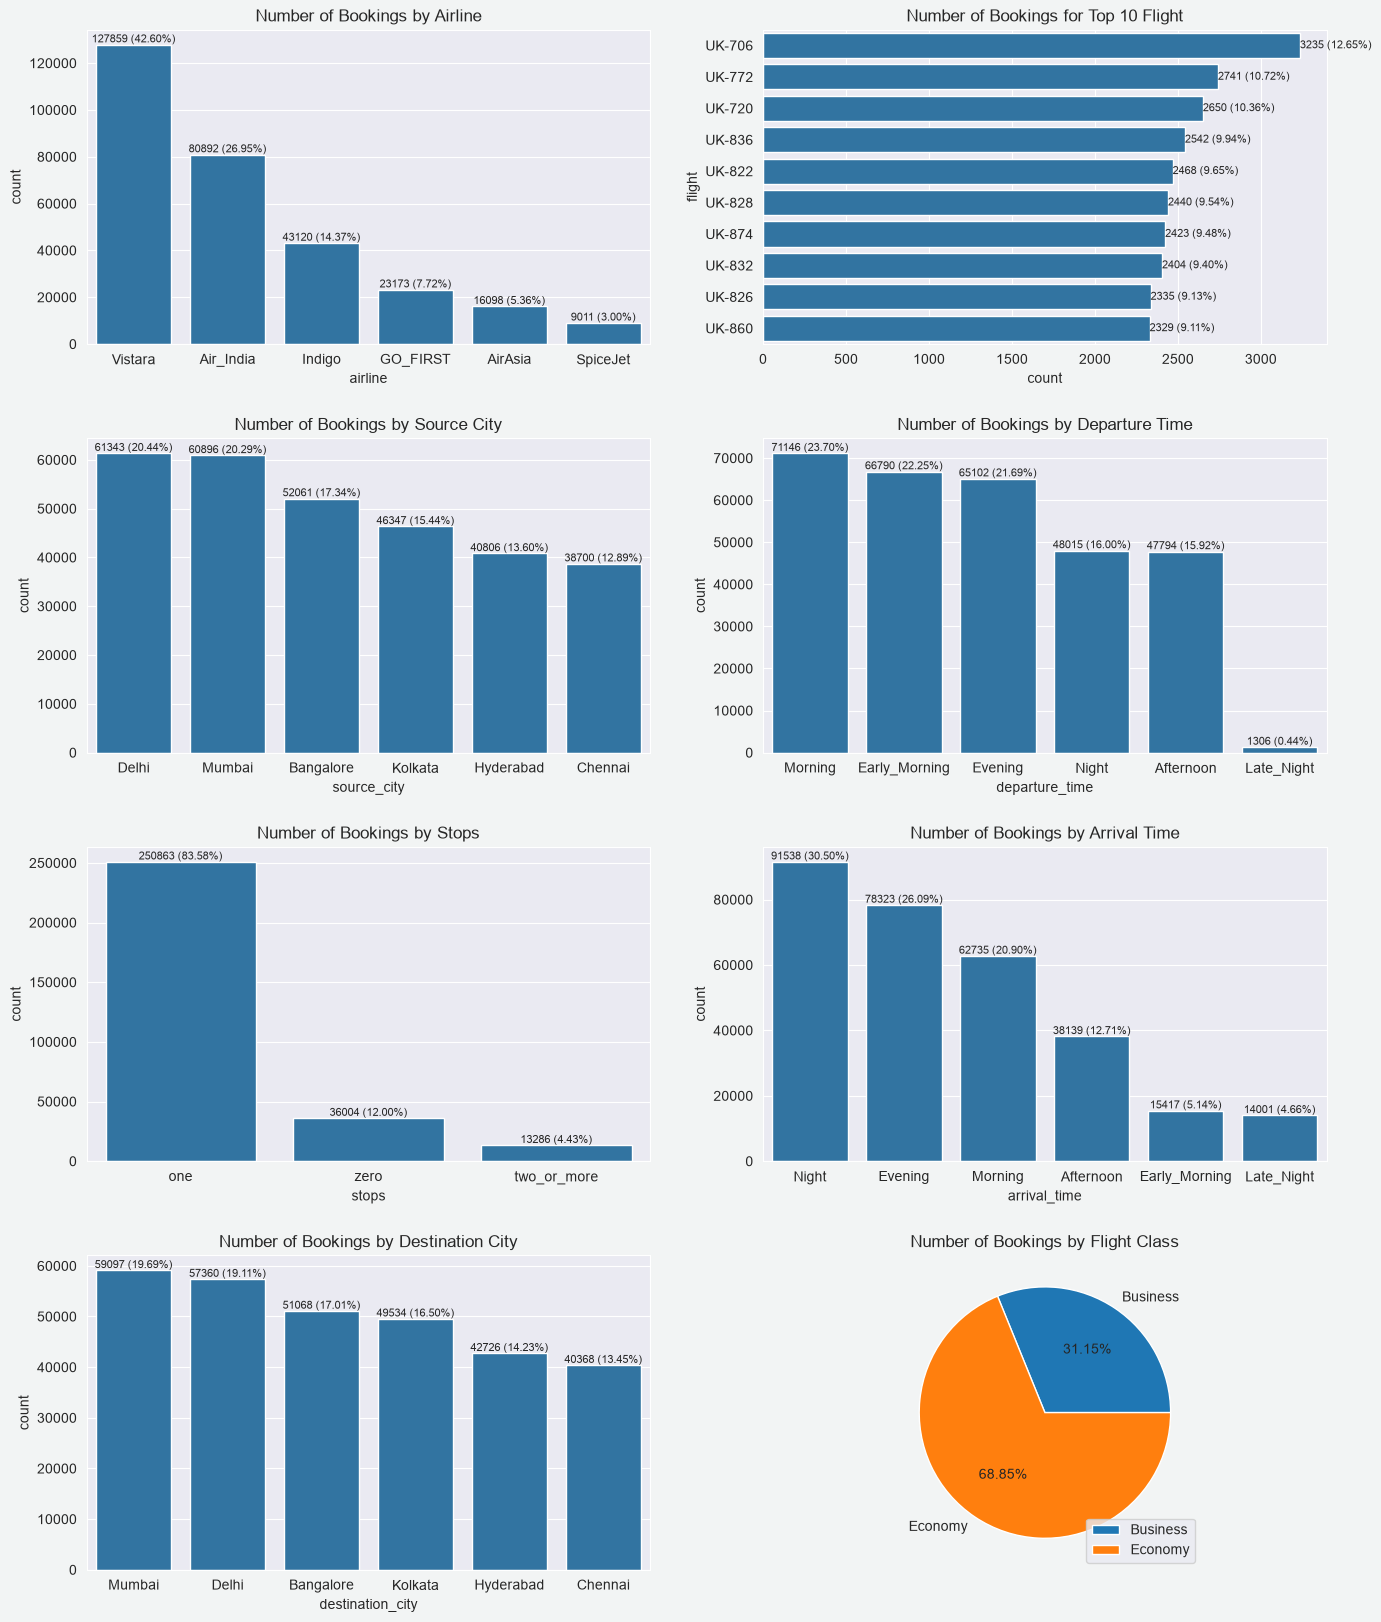

In [10]:
fig, ax = plt.subplots(4,2, figsize=(16,20), facecolor='#F2F4F4')
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.2, hspace=0.3)

abs_airline = fp['airline'].value_counts(ascending=False) # absolute (aka count)
a = sns.countplot(x='airline', data=fp, order=abs_airline.index, ax=ax[0,0])
rel_airline = fp['airline'].value_counts(ascending=False, normalize=True).values*100
lbs_airline = [f"{a[0]} ({a[1]:.2f}%)" for a in zip(abs_airline,rel_airline)]
a.set_title("Number of Bookings by Airline", fontsize=12)
a.bar_label(container=a.containers[0], labels=lbs_airline, fontsize=8);

top_10_flight = fp['flight'].value_counts().reset_index()[0:10]
top_10_flight = fp[fp['flight'].isin(np.array(top_10_flight['flight']))]
abs_flight = top_10_flight['flight'].value_counts(ascending=False)
f = sns.countplot(y='flight', data=top_10_flight, order=abs_flight.index, ax=ax[0,1])
rel_flight = top_10_flight['flight'].value_counts(ascending=False, normalize=True).values*100
lbs_flight = [f"{f[0]} ({f[1]:.2f}%)" for f in zip(abs_flight,rel_flight)]
f.set_title("Number of Bookings for Top 10 Flight", fontsize=12)
f.bar_label(container=f.containers[0], labels=lbs_flight, fontsize=8);

abs_source_city = fp['source_city'].value_counts(ascending=False)
s = sns.countplot(x='source_city', data=fp, order=abs_source_city.index, ax=ax[1,0])
rel_source_city = fp['source_city'].value_counts(ascending=False, normalize=True).values*100
lbs_source_city = [f"{s[0]} ({s[1]:.2f}%)" for s in zip(abs_source_city,rel_source_city)]
s.set_title("Number of Bookings by Source City", fontsize=12)
s.bar_label(container=s.containers[0], labels=lbs_source_city, fontsize=8);

abs_departure_time = fp['departure_time'].value_counts(ascending=False)
d = sns.countplot(x='departure_time', data=fp, order=abs_departure_time.index, ax=ax[1,1])
rel_departure_time = fp['departure_time'].value_counts(ascending=False, normalize=True).values*100
lbs_departure_time = [f"{d[0]} ({d[1]:.2f}%)" for d in zip(abs_departure_time, rel_departure_time)]
d.set_title("Number of Bookings by Departure Time", fontsize=12)
d.bar_label(container=d.containers[0], labels=lbs_departure_time, fontsize=8);
 
abs_stops = fp['stops'].value_counts(ascending=False)
t = sns.countplot(x='stops', data=fp, order=abs_stops.index, ax=ax[2,0])
rel_stops = fp['stops'].value_counts(ascending=False, normalize=True).values*100
lbs_stops = [f"{t[0]} ({t[1]:.2f}%)" for t in zip(abs_stops,rel_stops)]
t.set_title("Number of Bookings by Stops", fontsize=12)
t.bar_label(container=t.containers[0], labels=lbs_stops, fontsize=8);
 
abs_arrival_time = fp['arrival_time'].value_counts(ascending=False)
r = sns.countplot(x='arrival_time', data=fp, order=abs_arrival_time.index, ax=ax[2,1])
rel_arrival_time = fp['arrival_time'].value_counts(ascending=False, normalize=True).values*100
lbs_arrival_time = [f"{r[0]} ({r[1]:.2f}%)" for r in zip(abs_arrival_time,rel_arrival_time)]
r.set_title("Number of Bookings by Arrival Time", fontsize=12)
r.bar_label(container=r.containers[0], labels=lbs_arrival_time, fontsize=8);

abs_destination_city = fp['destination_city'].value_counts(ascending=False)
e = sns.countplot(x='destination_city', data=fp, order=abs_destination_city.index, ax=ax[3,0])
rel_destination_city = fp['destination_city'].value_counts(ascending=False, normalize=True).values*100
lbs_destination_city = [f"{e[0]} ({e[1]:.2f}%)" for e in zip(abs_destination_city,rel_destination_city)]
e.set_title("Number of Bookings by Destination City", fontsize=12)
e.bar_label(container=e.containers[0], labels=lbs_destination_city, fontsize=8);

class_cat = fp.groupby('class').agg({'class':'count'}).rename(columns={'class':'count'})
class_cat.plot.pie(y='count', autopct='%1.2f%%',ylabel="", ax=ax[3,1])
plt.title('Number of Bookings by Flight Class', fontsize=12)
plt.legend(loc='lower right');
# abs_class = fp['class'].value_counts(ascending=False)
# l = sns.countplot(x='class', data=fp, order=abs_class.index, ax=ax[3,1])
# rel_class = fp['class'].value_counts(ascending=False, normalize=True).values*100
# lbs_class = [f"{l[0]} ({l[1]:.2f}%)" for l in zip(abs_class,rel_class)]
# l.set_title("Number of Bookings by Flight Class", fontsize=12)
# l.bar_label(container=l.containers[0], labels=lbs_class, fontsize=8);

* Airline: Vistara dominates the market share at 42.60% (127,859 bookings), followed by Air India at 26.95% (80,892 bookings). SpiceJet has the lowest representation at 3.00% (9,011 bookings).   
* Source & Destination Cities: Bookings across major hubs (Delhi, Mumbai, Bangalore, Kolkata, Hyderabad, Chennai) are relatively balanced, ranging between 12% and 21% each, with Mumbai and Delhi slightly leading.   
* Stops: The vast majority of flights are one-stop (83.58% / 250,863 bookings), while zero-stop and two-or-more-stop flights make up 12.00% and 4.43%, respectively.   
* Departure & Arrival Times: Departures peak heavily in the Morning (23.70%) and Early Morning (22.25%), while Late Night flights are extremely rare (0.44%). Arrivals peak heavily at Night (30.50%) and Evening (26.09%).   
* Flight Class: The dataset leans heavily toward Economy (68.85%) compared to Business (31.15%).  

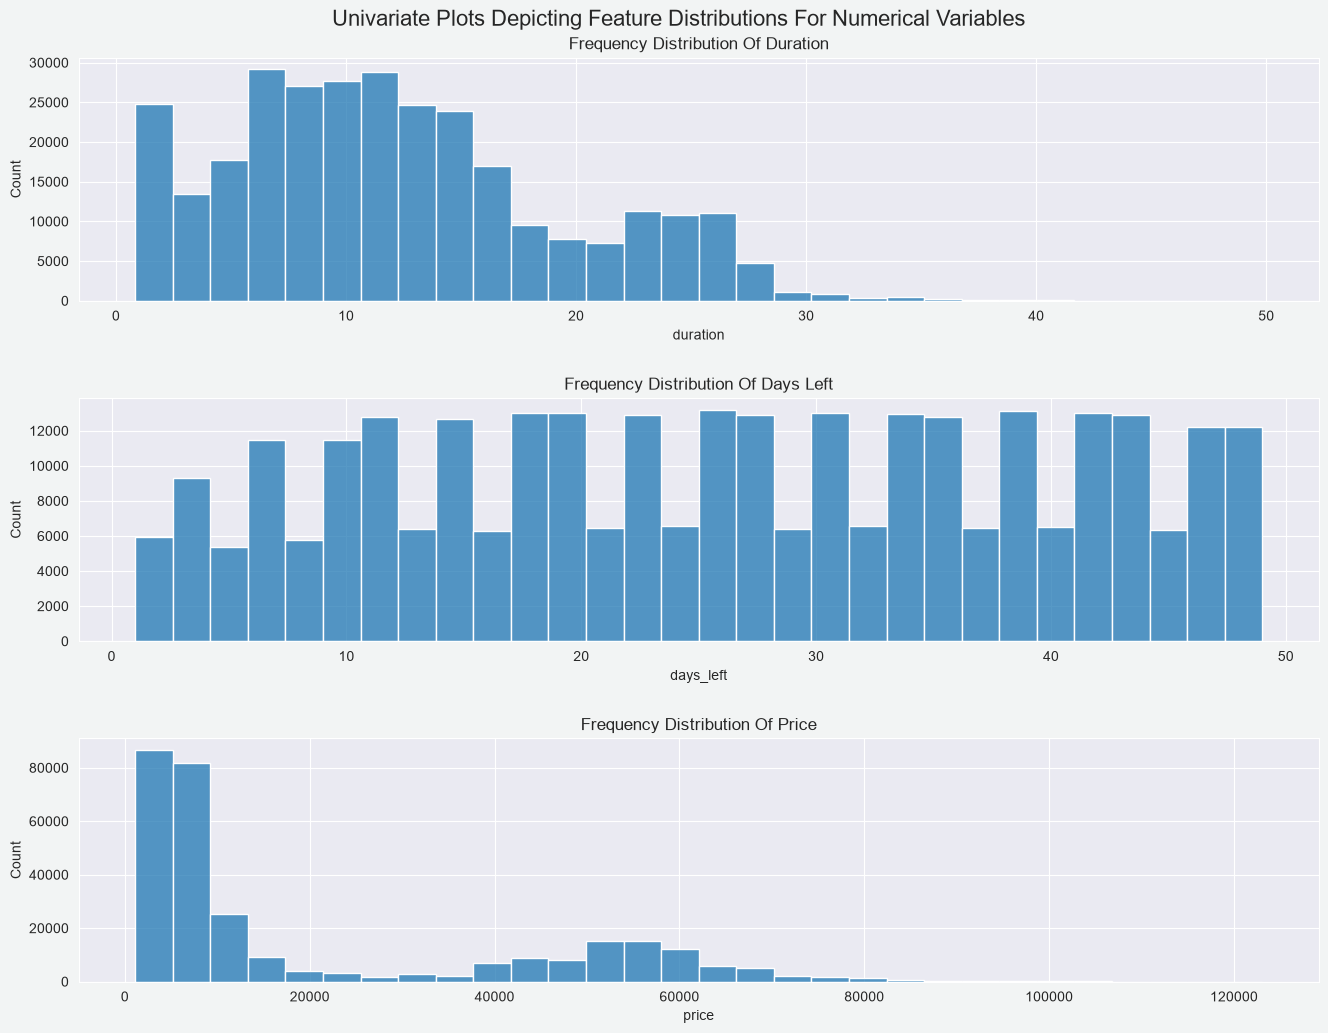

In [11]:
numeric_cols = fp.select_dtypes(include=['number']).columns

fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(16, 12), facecolor='#F2F4F4')
fig.subplots_adjust(hspace=0.4)

for idx, col in enumerate(numeric_cols):
    sns.histplot(data=fp, x=col, kde=False, bins=30, ax=axes[idx])
    axes[idx].set_title(f"Frequency Distribution Of {col}".title().replace("_", " "), fontsize=12)
    axes[idx].set_ylabel("Count")

fig.suptitle('Univariate Plots Depicting Feature Distributions For Numerical Variables', fontsize=16, y=0.92)
plt.show()

* Duration: Most flight durations cluster heavily between 2 to 20 hours, with frequent peaks at specific hour intervals. Very long durations (approaching 30 to 50 hours, likely involving heavy layovers or multi-stop connections) drop off significantly in frequency.

* Days Left (Booking Window): Bookings in this dataset are distributed evenly across all advance-booking timelines, meaning passengers book anywhere from last-minute to nearly two months in advance in roughly equal proportions.

* Price: The vast majority of ticket prices are concentrated on the lower end (peaking heavily between roughly ₹2,000 to ₹10,000), representing standard economy fares. The tail stretches out past ₹120,000, driven by high-tier business class tickets and luxury/last-minute surges.

# Multivariate Analysis

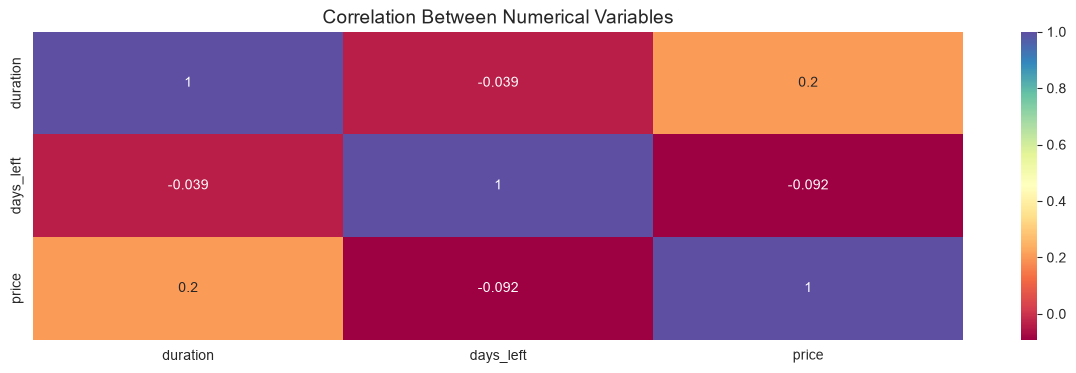

In [12]:
plt.figure(figsize = (15,4))
num_corr = fp[fp.select_dtypes(include=["number"]).columns].corr()
sns.heatmap(num_corr,annot=True,fmt='.2g', cmap="Spectral")
plt.title('Correlation Between Numerical Variables', fontsize=14);

* Duration vs. Price (0.20): A weak positive correlation, showing that longer flights tend to have slightly higher ticket prices.   
* Days Left vs. Price (-0.092): A very weak negative correlation, indicating minimal linear association between the advance booking window and price across the overall dataset.   
* Duration vs. Days Left (-0.039): Practically zero correlation, meaning flight duration and how far in advance a ticket is booked are completely independent of each other. 

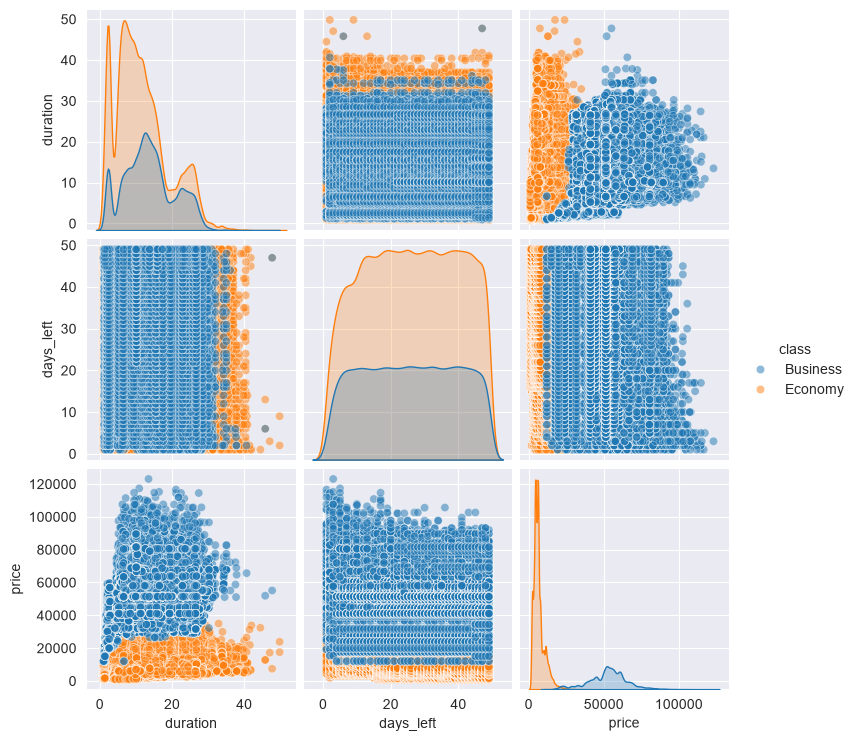

CPU times: total: 2min 19s
Wall time: 2min 16s


In [13]:
%%time
# Select numerical columns plus one categorical column for grouping (e.g., 'class')
cols_to_plot = ['duration', 'days_left', 'price', 'class']

# Generate the pairplot using raw data, color-coding by flight class
sns.pairplot(fp[cols_to_plot], hue='class',plot_kws={'alpha': 0.5})
plt.show()

* No linearity found, proposed to use ridge, lasso and elastic net regression with log transformation of target variable (price). 
* Otherwise, we need to use the RandomForest regressor, SVM regressor or XG Boost regressor.

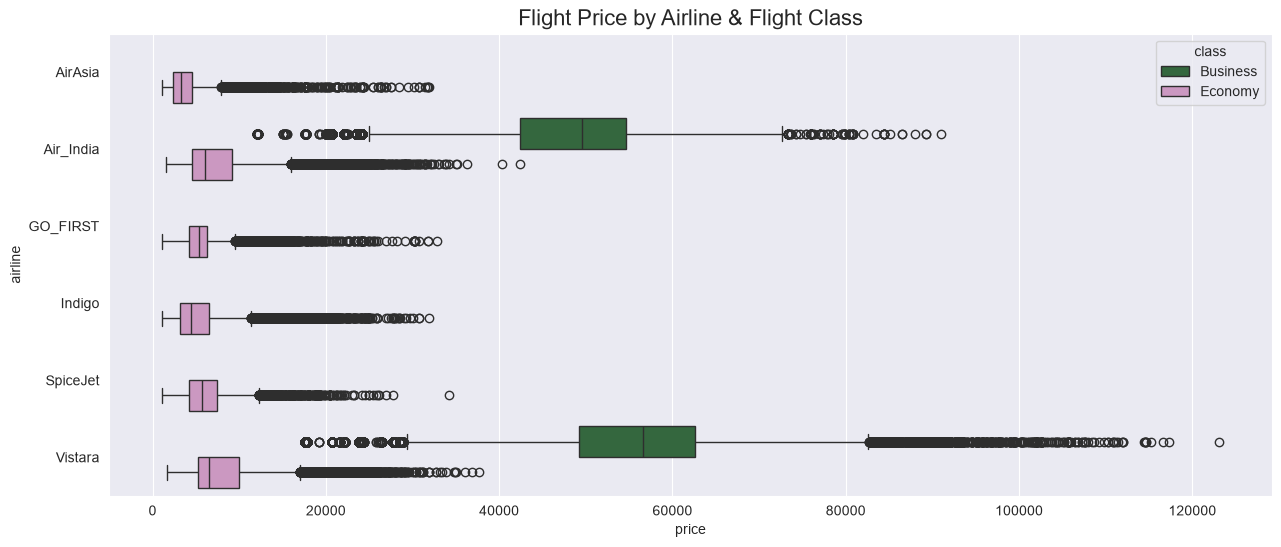

In [14]:
# How does the ticket price vary with Airlines and flight class?
plt.figure(figsize = (15,6))
sns.boxplot(y=fp['airline'], x=fp['price'], hue=fp['class'], palette="cubehelix")
plt.title('Flight Price by Airline & Flight Class', fontsize=16);

In [15]:
min = fp[['airline', 'class','price']].groupby(['airline','class']).agg({'price':'min'}).rename({'price':'min_price'},axis=1)
max = fp[['airline','class','price']].groupby(['airline', 'class']).agg({'price':'max'}).rename({'price':'max_price'},axis=1)
pd.concat([min,max], axis=1).sort_values('min_price')

,,min_price,max_price
airline,class,,
AirAsia,Economy,1105,31917
GO_FIRST,Economy,1105,32803
Indigo,Economy,1105,31952
SpiceJet,Economy,1106,34158
Air_India,Economy,1526,42349
Vistara,Economy,1714,37646
Air_India,Business,12000,90970
Vistara,Business,17604,123071


* It is found that only Vistara and Air India provide flight with business class, but the maximum price for the business flight of the Vistara is higher than that of the business flight of the Air India. 
* When we compared the maximum economy flight price from each airline, we found that economy flight ticket from the AirAsia, GO First, and Indigo offered the same lowest price, which is $1,105.00.

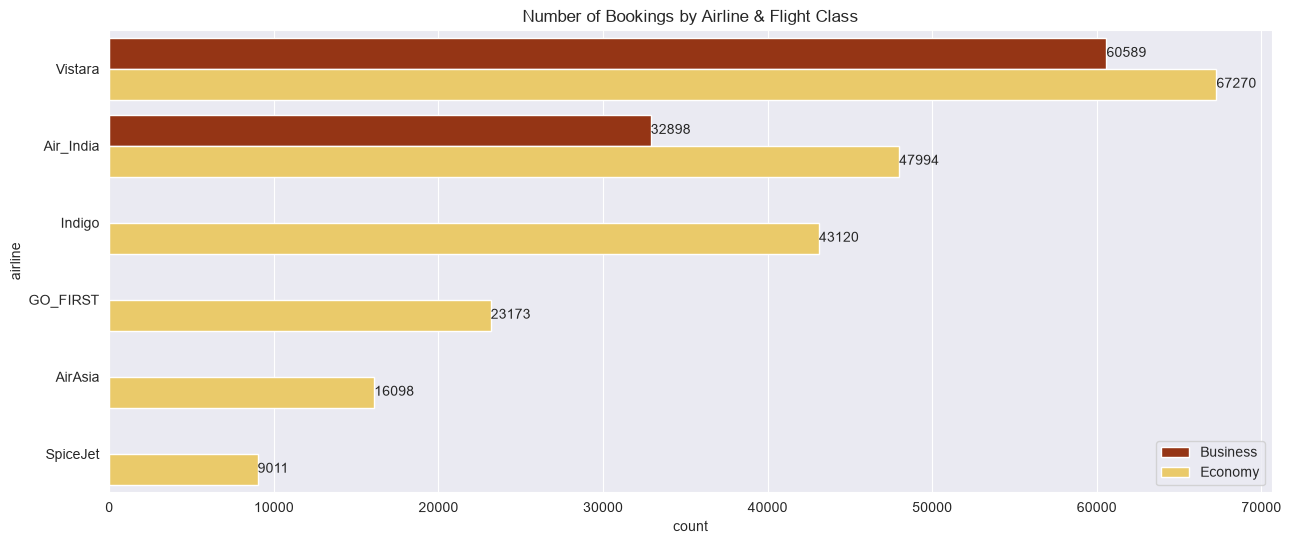

In [16]:
# How many bookings based on Airlines and flight class?
plt.figure(figsize = (15,6))
b = sns.countplot(y='airline', data=fp, order=abs_airline.index, hue='class', palette="afmhot")
b.set_title("Number of Bookings by Airline & Flight Class", fontsize=12)
b.bar_label(container=b.containers[0])
b.bar_label(container=b.containers[1])
plt.legend(loc='lower right');

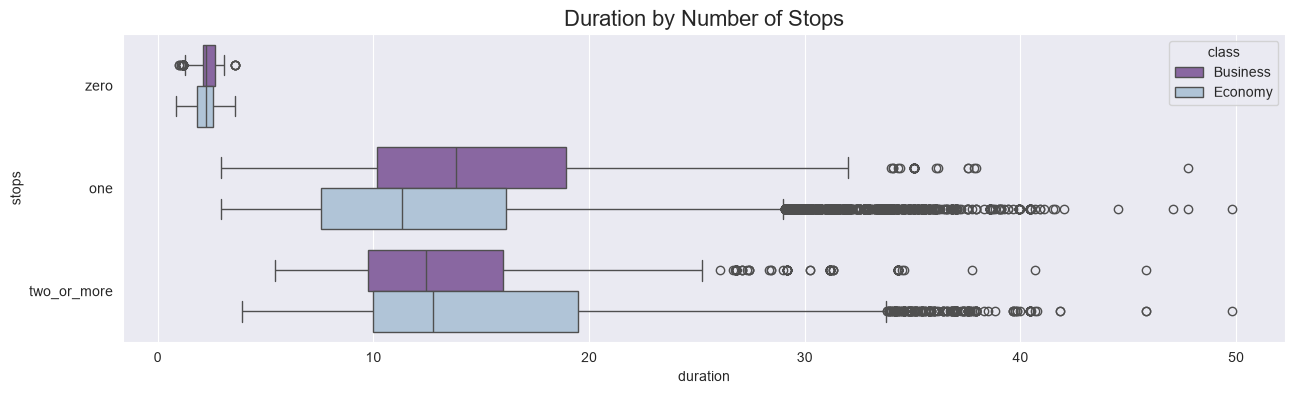

In [17]:
plt.figure(figsize = (15,4))
sns.boxplot(y="stops", x="duration", hue='class', data=fp, palette='BuPu_r')
plt.title('Duration by Number of Stops', fontsize=16);

In [18]:
# fp.sort_values('duration', ascending=False).head(10)
min_period = fp[['stops', 'class','duration']].groupby(['stops','class']).agg({'duration':'min'}).rename({'duration':'min_duration'},axis=1)
max_period = fp[['stops','class','duration']].groupby(['stops', 'class']).agg({'duration':'max'}).rename({'duration':'max_duration'},axis=1)
pd.concat([min_period,max_period], axis=1)

min_duration  max_duration
stops       class                               
zero        Business          1.00          3.58
            Economy           0.83          3.58
one         Business          2.92         47.75
            Economy           2.92         49.83
two_or_more Business          5.42         45.83
            Economy           3.92         49.83

In [19]:
nonstop_maxduration = fp[(fp.stops=='zero')].duration.max()
print(f"The maximum duration for flight with no stops is only {nonstop_maxduration} hours.")
flight_name = fp[(fp.stops=='zero') & (fp.duration==nonstop_maxduration)]['flight'].unique()[0]
airline = fp[(fp.stops=='zero') & (fp.duration==nonstop_maxduration)]['airline'].unique()[0]
departure_city = fp[(fp.stops=='zero') & (fp.duration==nonstop_maxduration)]['source_city'].unique()[0]
departure_time = fp[(fp.stops=='zero') & (fp.duration==nonstop_maxduration)]['departure_time'].unique()[0].lower()  
destination = fp[(fp.stops=='zero') & (fp.duration==nonstop_maxduration)]['destination_city'].unique()[0]
arrival_time = fp[(fp.stops=='zero') & (fp.duration==nonstop_maxduration)]['arrival_time'].unique()[0].lower()
print(f"The flight was {flight_name} from {airline} which fled from {departure_city} at {departure_time} and arrived {destination} at {arrival_time}.")

The maximum duration for flight with no stops is only 3.58 hours.
The flight was AI-773 from Air_India which fled from Kolkata at evening and arrived Mumbai at night.


<Figure size 1500x2000 with 0 Axes>

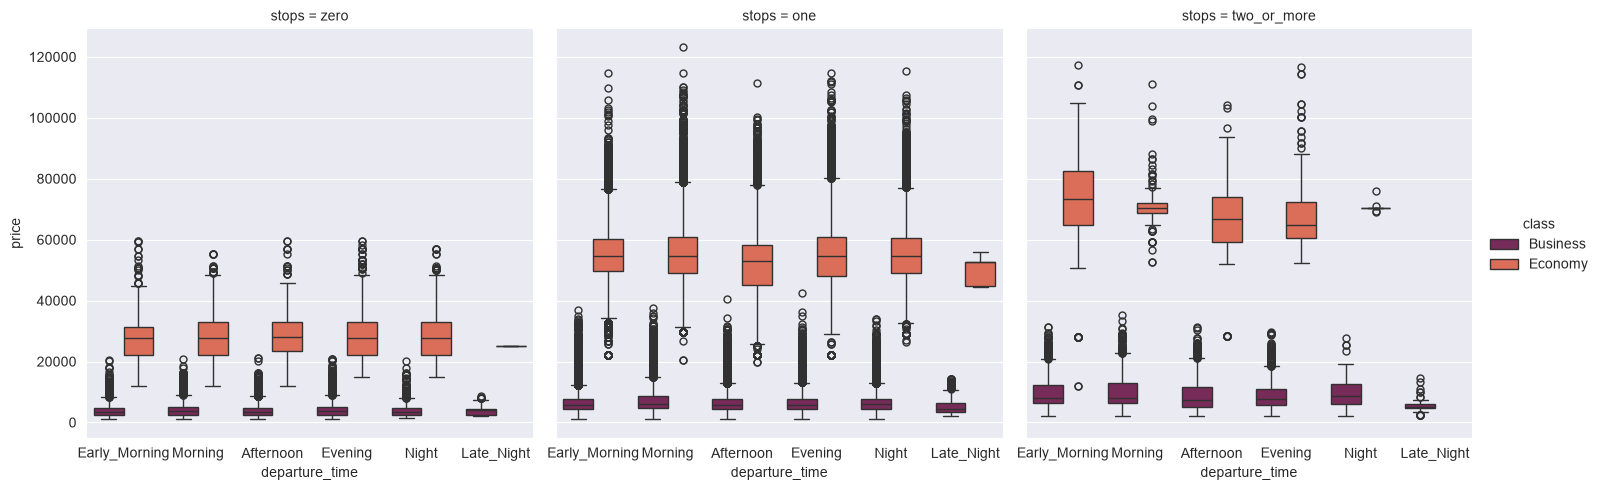

In [20]:
# How does the ticket price vary with number of stops, flight class, and departure time?
plt.figure(figsize = (15,20))
sns.catplot(x="departure_time", y="price", hue='class', col='stops', data=fp, kind="box", palette='rocket');

* From the 3rd graph, flight with business class, two or more stops and early morning departure time have the highest maximum price as compared to other flights. 
* There is no business class flight with two or more stops that depart at late night. 

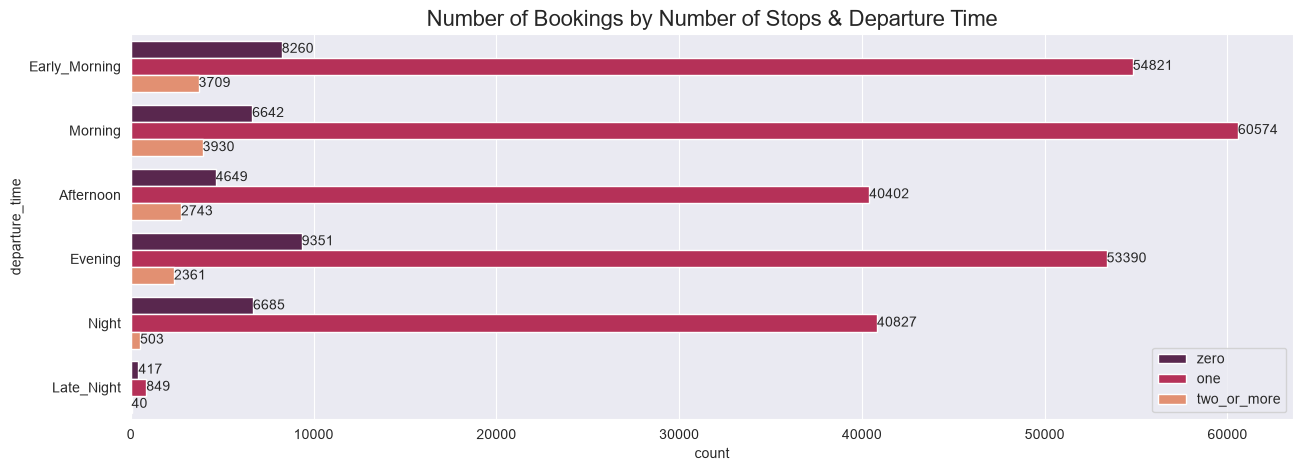

In [21]:
plt.figure(figsize = (15,5))
abs_departure_time = fp['departure_time'].value_counts(ascending=False)
c = sns.countplot(y='departure_time', data=fp, hue='stops', palette='rocket')
c.set_title("Number of Bookings by Number of Stops & Departure Time", fontsize=16)
c.bar_label(container=c.containers[0])
c.bar_label(container=c.containers[1])
c.bar_label(container=c.containers[2])
plt.legend(loc='lower right');

<Figure size 1500x2000 with 0 Axes>

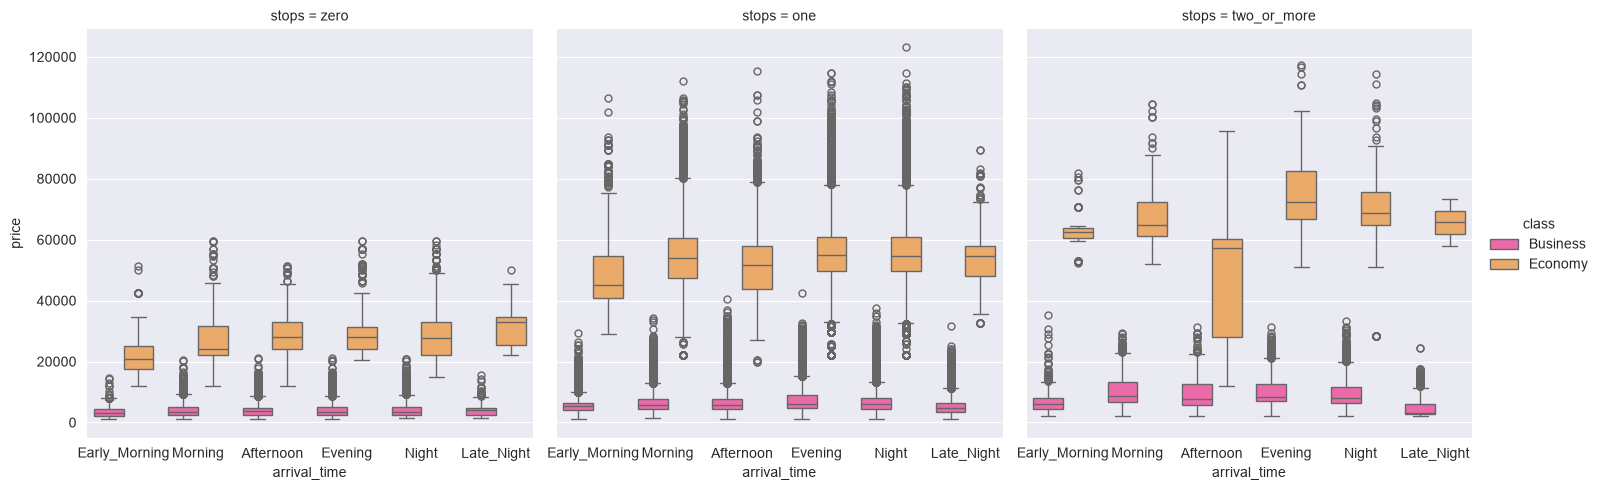

In [22]:
# # How does the ticket price vary with number of stops, flight class, and arrival time?
plt.figure(figsize = (15,20))
sns.catplot(x="arrival_time", y="price", hue='class', col='stops', data=fp, kind="box", palette='spring');

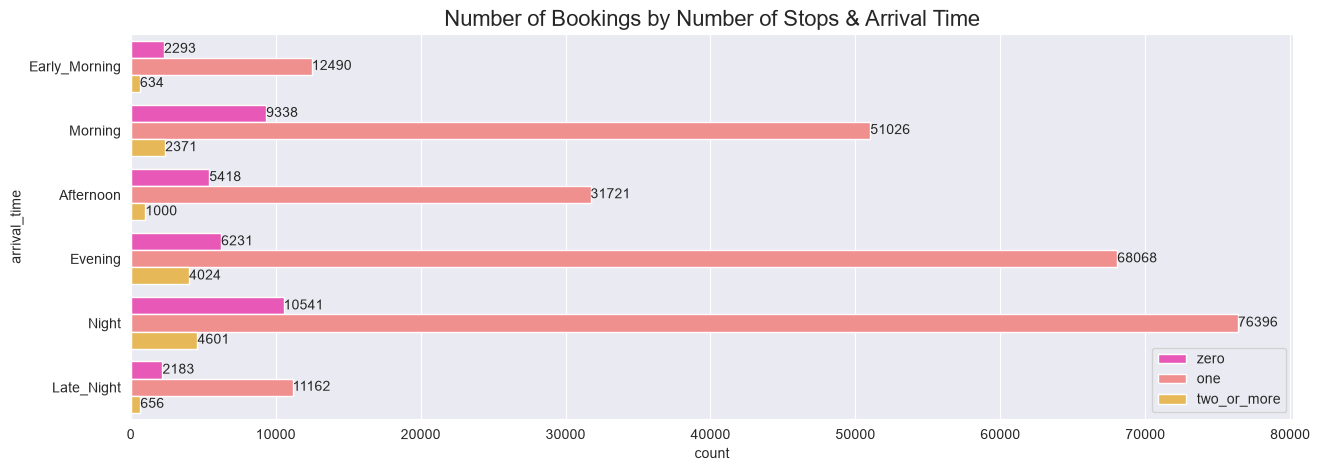

In [23]:
plt.figure(figsize = (15,5))
abs_departure_time = fp['arrival_time'].value_counts(ascending=False)
g = sns.countplot(y='arrival_time', data=fp, hue='stops', palette='spring')
g.set_title("Number of Bookings by Number of Stops & Arrival Time", fontsize=16)
g.bar_label(container=g.containers[0])
g.bar_label(container=g.containers[1])
g.bar_label(container=g.containers[2])
plt.legend(loc='lower right');

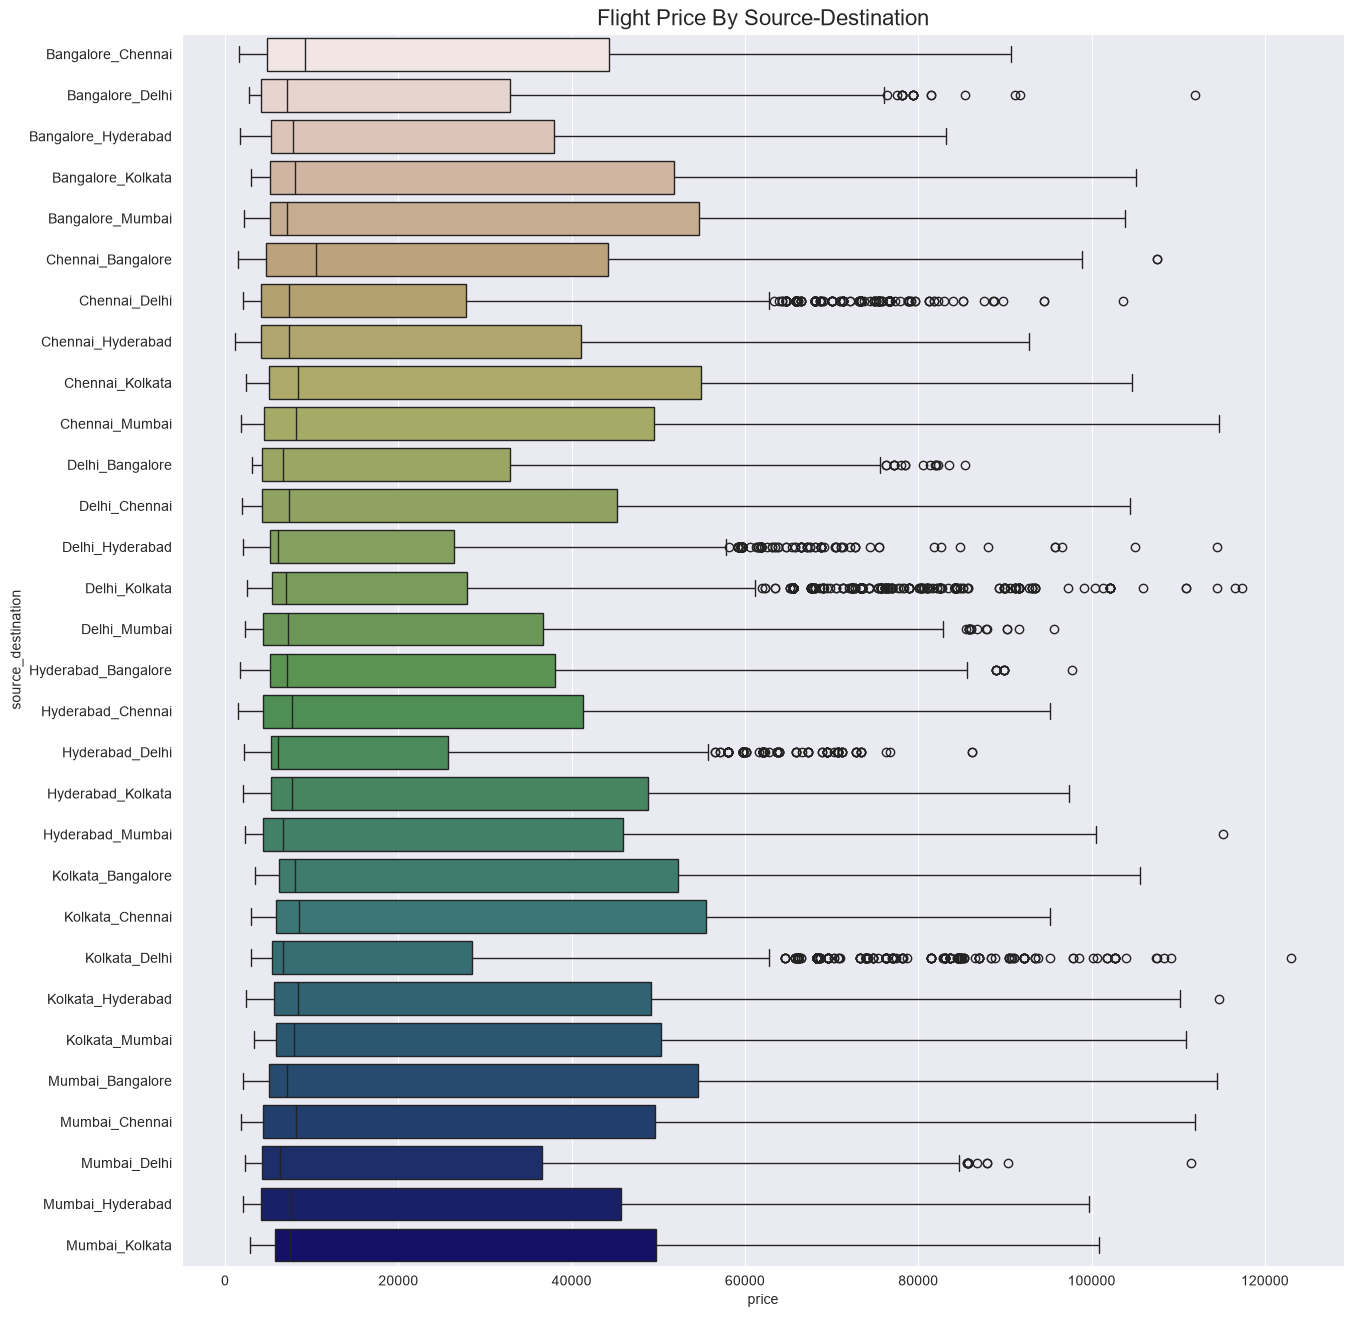

In [24]:
# How the price changes with change in Source and Destination?
plt.figure(figsize = (15,16))
sns.boxplot(y="source_destination", x="price", data=fp, palette='gist_earth_r')
plt.title('Flight Price By Source-Destination', fontsize=16)
plt.show()

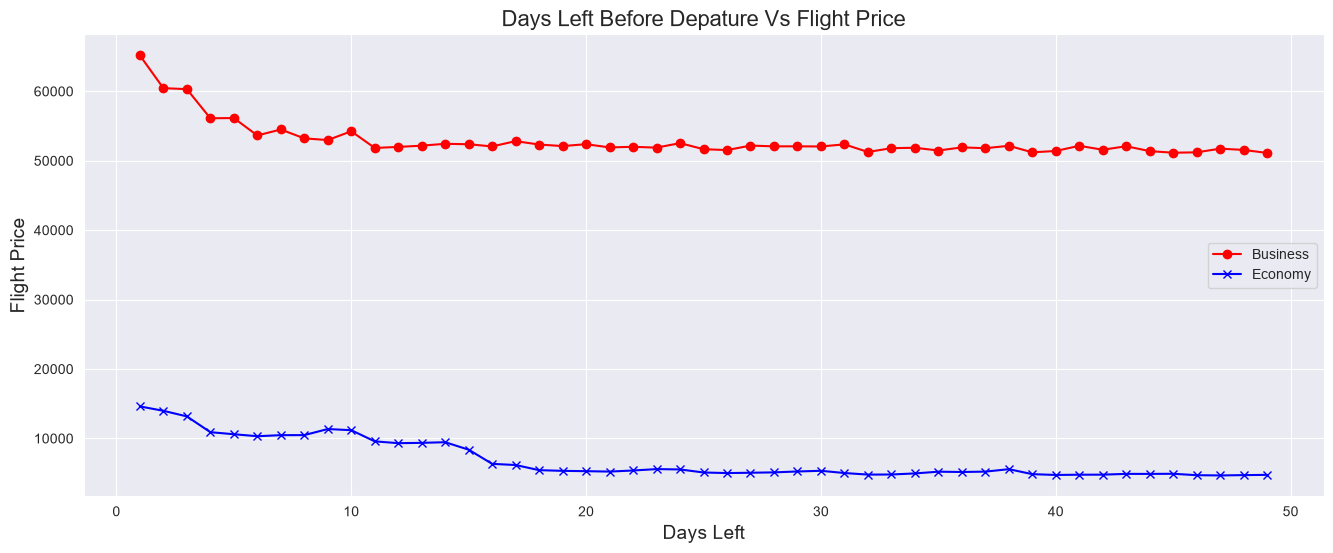

In [25]:
# How does the price vary with days left before departure?
dc = fp.groupby(['class','days_left']).agg({'price':'mean'}).reset_index()
plt.figure(figsize = (16,6))
plt.plot(dc[dc['class']=='Business']['days_left'], dc[dc['class']=='Business']['price'], color='red', marker='o', label='Business')
plt.plot(dc[dc['class']=='Economy']['days_left'], dc[dc['class']=='Economy']['price'], color='blue', marker='x', label='Economy')
plt.title('Days Left Before Depature Vs Flight Price', fontsize=16)
plt.xlabel('Days Left', fontsize=14)
plt.ylabel('Flight Price', fontsize=14)
plt.legend(loc='center right');

In [26]:
# How is the price affected when tickets are bought in just 1 or 2 days before departure?
fp[(fp['days_left']==1)|(fp['days_left']==2)].groupby(['airline', 'stops','class']).agg({'price':'mean'}).sort_values('price',ascending=False)

price
airline   stops       class                 
Vistara   two_or_more Business  82788.837838
          one         Business  71237.325737
Air_India two_or_more Business  69021.875000
          one         Business  56008.441828
Vistara   zero        Business  35977.843373
Air_India zero        Business  28332.855263
Vistara   two_or_more Economy   20484.470085
Air_India two_or_more Economy   17656.106796
Vistara   one         Economy   16542.035436
Indigo    two_or_more Economy   15982.523810
Air_India one         Economy   15077.854437
Indigo    one         Economy   14162.878531
GO_FIRST  one         Economy   13076.853933
SpiceJet  one         Economy   13005.575581
AirAsia   one         Economy   11011.066667
Indigo    zero        Economy    9025.528369
AirAsia   two_or_more Economy    8895.700000
Vistara   zero        Economy    8510.685484
Air_India zero        Economy    8314.693182
SpiceJet  zero        Economy    8220.862745
AirAsia   zero        Economy    7653.395833
GO_FIRST  zero        Economy    6728.930233

# Model Building & Evaluation

In [27]:
# Identify input and target columns
fp_d = fp.drop(['flight','source_destination'], axis=1)
input_cols, target_col = fp_d.columns[0:-1], fp_d.columns[-1]
X, Y = fp[input_cols].copy(), fp[target_col].copy()

In [28]:
# Identify numeric and categorical columns
num_cols = X.select_dtypes(np.number).columns.to_list()
cat_cols = X.select_dtypes(include=['category','string']).columns.to_list()
print("numerical:", num_cols)
print("categorical:", cat_cols)

numerical: ['duration', 'days_left']
categorical: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']


In [29]:
# Create training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)
X_train, X_val, Y_train, Y_val = train_test_split(X_train, Y_train, test_size=0.25, random_state=42)

print("Training data: ", X_train.shape) # 60%
print("Validation data", X_val.shape) # 20%
print("Testing data: ", X_test.shape) # 20%
print("Total Size: ", X_train.shape[0] + X_test.shape[0]+X_val.shape[0])

Training data:  (180091, 9)
Validation data (60031, 9)
Testing data:  (60031, 9)
Total Size:  300153


In [30]:
trans = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), num_cols),
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)
print(trans)

ColumnTransformer(remainder='passthrough',
                  transformers=[('num', MinMaxScaler(),
                                 ['duration', 'days_left']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['airline', 'source_city', 'departure_time',
                                  'stops', 'arrival_time', 'destination_city',
                                  'class'])])


In [31]:
# 1. Define base models and their specific hyperparameter tuning grids
model_configs = {
    "Ridge": {
        "model": Ridge(random_state=42),
        "params": {"regressor__regressor__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]}
    },
    "Lasso": {
        "model": Lasso(random_state=42),
        "params": {"regressor__regressor__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]}
    },
    "ElasticNet": {
        "model": ElasticNet(random_state=42),
        "params": {
            "regressor__regressor__alpha": [0.001, 0.01, 0.1, 1.0, 10.0],
            "regressor__regressor__l1_ratio": [0.2, 0.5, 0.8]
        }
    }
}

# Dictionary to store the best-tuned models after the loop
best_models = {}

In [32]:
%%time
# Run the loop for each model
for name, config in model_configs.items():
    print(f"--- Training and Tuning: {name} ---")
    
    # Build the inner pipeline (Preprocessor + Regressor)
    pipe = Pipeline(steps=[
        ('preprocessor', trans),  # Your ColumnTransformer
        ('regressor', config["model"])
    ])
    
    # Wrap with target transformation for log(y)
    log_model = TransformedTargetRegressor(
        regressor=pipe,
        func=np.log,
        inverse_func=np.exp
    )
    
    # Set up GridSearchCV
    grid_search = GridSearchCV(
        estimator=log_model,
        param_grid=config["params"],
        cv=3,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    # Fit on training data (using raw data X_train, Y_train)
    grid_search.fit(X_train, Y_train)
    
    # Save the best model
    best_models[name] = grid_search.best_estimator_
    
    # Print results
    print(f"Best Hyperparameters for {name}: {grid_search.best_params_}")
    print(f"Best CV Score (Negative MAE): {-grid_search.best_score_:.2f}\n")

--- Training and Tuning: Ridge ---
Best Hyperparameters for Ridge: {'regressor__regressor__alpha': 10.0}
Best CV Score (Negative MAE): 4562.08

--- Training and Tuning: Lasso ---
Best Hyperparameters for Lasso: {'regressor__regressor__alpha': 0.01}
Best CV Score (Negative MAE): 4374.92

--- Training and Tuning: ElasticNet ---
Best Hyperparameters for ElasticNet: {'regressor__regressor__alpha': 0.01, 'regressor__regressor__l1_ratio': 0.5}
Best CV Score (Negative MAE): 4351.59

CPU times: total: 8.73 s
Wall time: 1min 4s


In [33]:
# 1. Define models and their respective hyperparameter tuning grids
models = {
    "Decision Tree": {
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            "regressor__max_depth": [10, 20, None],
            "regressor__min_samples_split": [2, 10],
            "regressor__min_samples_leaf":[1, 2, 4]
        }
    },
    "Random Forest": {
        "model": RandomForestRegressor(random_state=42, n_jobs=-1),
        "params": {
            "regressor__n_estimators": [100, 150, 200],
            "regressor__max_features":['sqrt','log2',0.5]
        }
    },
    #"KNN": {
    #    "model": KNeighborsRegressor(n_jobs=-1),
    #    "params": {
    #        "regressor__n_neighbors": [3, 5, 9],
    #        "regressor__weights": ['uniform', 'distance']
    #    }
    #},
    #"SVM": {
    #    "model": SVR(),
    #    "params": {
    #        "regressor__C": [1.0, 10.0],
    #        "regressor__kernel": ['rbf', 'linear']
    #    }
    #},
    "XGBoost": {
        "model": XGBRegressor(random_state=42, n_jobs=-1, eval_metric='mae'),
        "params": {
            "regressor__n_estimators": [300, 500],
            "regressor__learning_rate": [0.05, 0.01],
            "regressor__max_depth": [3, 5]
        }
    }
}

# Dictionary to store trained grid search objects
best_advanced_models = {}

In [34]:
%%time

for name, config in models.items():
    print(f"=== Tuning: {name} ===")
    
    # Build pipeline: Preprocessor + Model
    pipe = Pipeline(steps=[
        ('preprocessor', trans), # ColumnTransformer
        ('regressor', config["model"])
    ])
    
    # Set up GridSearchCV with 5-Fold CV and negative MAE
    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=config["params"],
        cv=3,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        return_train_score=False
    )
    
    # Fit on training data
    grid_search.fit(X_train, Y_train)

    # Extract mean and std of the BEST performing hyperparameter combination across folds
    best_index = grid_search.best_index_
    mean_mae = -grid_search.cv_results_['mean_test_score'][best_index]
    std_mae = grid_search.cv_results_['std_test_score'][best_index]
    
    # Save the best estimator
    best_advanced_models[name] = grid_search.best_estimator_
    
    print(f"Best Params for {name}: {grid_search.best_params_}")
    # print(f"Best CV Score (MAE): {-grid_search.best_score_:.2f}\n")
    print(f"Best CV Score (MAE): {mean_mae:.2f} (+/- {std_mae:.2f})\n")

=== Tuning: Decision Tree ===
Best Params for Decision Tree: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2}
Best CV Score (MAE): 1298.11 (+/- 5.44)

=== Tuning: Random Forest ===
Best Params for Random Forest: {'regressor__max_features': 0.5, 'regressor__n_estimators': 200}
Best CV Score (MAE): 1233.42 (+/- 7.49)

=== Tuning: XGBoost ===
Best Params for XGBoost: {'regressor__learning_rate': 0.05, 'regressor__max_depth': 5, 'regressor__n_estimators': 500}
Best CV Score (MAE): 2283.79 (+/- 4.75)

CPU times: total: 5min 5s
Wall time: 14min 37s


In [35]:
voting_regressor_rfxg = VotingRegressor(
    estimators=[
        ('rf', best_advanced_models['Random Forest'].named_steps['regressor']),
        ('xgb', best_advanced_models['XGBoost'].named_steps['regressor'])
    ],
    weights=[2, 3]
)

voting_regressor_dtxg = VotingRegressor(
    estimators=[
        ('dt', best_advanced_models['Decision Tree'].named_steps['regressor']),
        ('xgb', best_advanced_models['XGBoost'].named_steps['regressor'])
    ],
    weights=[2, 3]
)

In [36]:
models_list={
    "Voting Regressor (RF+XGB)": voting_regressor_rfxg,
    "Voting Regressor (DT+XGB)": voting_regressor_dtxg,
    "Random Forest":best_advanced_models['Random Forest'].named_steps['regressor'],
    "Decision Tree":best_advanced_models['Decision Tree'].named_steps['regressor'],
    "XGBoost":best_advanced_models['XGBoost'].named_steps['regressor']}

In [37]:
%%time
for i,j in models_list.items():
    pipe = Pipeline(steps=[
        ('preprocessor', trans), # ColumnTransformer
        ('regressor', j)
    ])
    
    cv_scores = cross_val_score(
        pipe,
        X_val,
        Y_val,
        cv=3,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    
    # 1. Flip negative scores to positive MAE
    mean_cv_mae = -cv_scores.mean()
    
    # 2. Calculate the standard deviation across the CV folds
    std_mae = cv_scores.std()
    
    # 3. Print the results cleanly
    print(f"{i} - Best CV Score (MAE): {mean_cv_mae:.2f} (+/- {std_mae:.2f})\n")

Voting Regressor (RF+XGB) - Best CV Score (MAE): 1960.89 (+/- 15.91)

Voting Regressor (DT+XGB) - Best CV Score (MAE): 1938.23 (+/- 17.21)

Random Forest - Best CV Score (MAE): 1591.10 (+/- 13.55)

Decision Tree - Best CV Score (MAE): 1710.22 (+/- 18.05)

XGBoost - Best CV Score (MAE): 2339.32 (+/- 18.54)

CPU times: total: 1.03 s
Wall time: 1min 28s


In [38]:
# Evaluate tuned Random Forest on the test set
final_model = best_advanced_models["Random Forest"] 
print(final_model)
y_pred_rf = final_model.predict(X_test)
test_mae_rf = mean_absolute_error(Y_test, y_pred_rf)
print(f"Random Forest - Test MAE: {test_mae_rf:.2f}")

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', MinMaxScaler(),
                                                  ['duration', 'days_left']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['airline', 'source_city',
                                                   'departure_time', 'stops',
                                                   'arrival_time',
                                                   'destination_city',
                                                   'class'])])),
                ('regressor',
                 RandomForestRegressor(max_features=0.5, n_estimators=200,
                                       n_jobs=-1, random_stat

<b>We can compute a 95% confidence interval for the test MAE:</b>

In [39]:
#  Generate predictions on your test set first
y_pred_test = final_model.predict(X_test)

#  Now run the bootstrap confidence interval code
y_test_arr = np.array(Y_test)
y_pred_arr = np.array(y_pred_test)

n_bootstraps = 1000
bootstrap_maes = []

np.random.seed(42)
n_size = len(y_test_arr)

for _ in range(n_bootstraps):
    indices = np.random.randint(0, n_size, n_size)
    mae = mean_absolute_error(y_test_arr[indices], y_pred_arr[indices])
    bootstrap_maes.append(mae)

ci_lower = np.percentile(bootstrap_maes, 2.5)
ci_upper = np.percentile(bootstrap_maes, 97.5)

actual_test_mae = mean_absolute_error(y_test_arr, y_pred_arr)

print(f"Test MAE: {actual_test_mae:.2f}")
print(f"95% Confidence Interval for MAE: [{ci_lower:.2f}, {ci_upper:.2f}]")

Test MAE: 1169.56
95% Confidence Interval for MAE: [1148.35, 1190.97]


# Making Predictions on New Inputs

In [40]:
def predict(model, single_input):
    input_df = pd.DataFrame([single_input])
    pred = model.predict(input_df)[0]
    return pred

In [41]:
new_input = {'airline': 'Air_India',
             'source_city': 'Chennai',
             'departure_time': 'Morning',
             'stops': 'one',
             'arrival_time': 'Late_Night',
             'destination_city': 'Mumbai',
             'class': 'Business',
             'duration':11.25,
             'days_left': 26}

print("The predicted price is",round(predict(final_model, new_input),2))

The predicted price is 50264.5


In [42]:
new_input_2 = {'airline': 'Vistara',
               'source_city': 'Chennai',
               'departure_time': 'Morning',
               'stops': 'one',
               'arrival_time': 'Late_Night',
               'destination_city': 'Mumbai',
               'class': 'Business',
               'duration':11.25,
               'days_left': 26}
print("The predicted price is",round(predict(final_model, new_input_2),2))

The predicted price is 68968.51


In [44]:
import nbconvert

# Recommendation

* We could implement other ML algorithms, such as KNeighborsRegressor, or support vector regressor. 
* Ensemble methods such as stacking regressor and voting regressor could be used to check if the model performance could be further improved.  
* Randomized Search could be used to tune the hyperparameters to see if the hyperparameter combination is the same. 